# Monocular depth 2: benchmarking five models on TUM RGB-D

Notebook 01 compared the models on a single frame. This notebook analyses a proper benchmark:
**96 frames** (48 evenly spaced frames from each of `fr1_desk` and `fr1_xyz`), five Depth
Anything models, and every alignment protocol, with **end-to-end latency and peak VRAM** per model.

**What this notebook does**
1. Loads the results written by `scripts/eval_tum.py`. Inference over all frames takes a few
   minutes, so it lives in a script, and the committed CSV/JSON files are what the README quotes.
2. Compares accuracy (AbsRel, RMSE, $\delta_1$) per model, protocol and sequence, against latency and VRAM.
3. Studies what a robot cares about beyond the average: the **frame-to-frame stability of the
   scale**, the error as a function of **distance**, and the **camera intrinsics** that DA3 estimates.
4. Re-runs three models on the worst frames to show **failure cases**: motion blur, reflective screens, thin structures, and the far range.

**What you'll learn**
- How to set up a fair depth benchmark: one valid-pixel mask for all models, alignment in each model's native space, and timing with CUDA synchronisation.
- Why "relative depth + per-frame alignment" numbers overstate what a robot gets at run time.
- How to look for failure modes systematically instead of anecdotally.

**Prerequisites**: notebook 01 (output types, alignment, metrics). Run the benchmark script first (see *How the numbers were produced*).

## Setup

In [1]:
# --- Setup: imports, device, repo-relative paths and plotting style ---
# The benchmark numbers come from CSV/JSON files; the GPU is only used again for the
# failure-case section.
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import device as cv_device
from cvlab import viz
from cvlab.io import load_json, project_dir, repo_root

device = cv_device.setup(seed=0)
viz.set_style()
PROJECT = "08_monocular_depth"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import mono_depth as md  # project helpers: models, alignment, metrics

RESULTS = project_dir(PROJECT) / "results"
print("results:", RESULTS.relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
results: projects/08_monocular_depth/results


## How the numbers were produced

```bash
flock /tmp/cv-gpu.lock python projects/08_monocular_depth/scripts/eval_tum.py
```

The protocol is set in `configs/eval_tum.yaml`.
- **Frames**: 48 evenly spaced frames per sequence, covering the whole trajectory. All models see exactly the same RGB images and the same GT mask ($0.1 < z^* < 10$ m, sensor holes excluded).
- **Models**: each model is loaded once and run on one frame at a time (batch size 1), under bf16 autocast, at its default resolution (DA3: longest side 504 px; DA-V2: short side 518 px). Outputs are resized bilinearly back to 640x480.
- **Alignment**: as in notebook 01. LSQ scale+shift in inverse depth for DA-V2 relative; median scale or LSQ in depth for DA3 relative; raw or median-scaled for the metric models.
- **Peak VRAM**: `torch.cuda.max_memory_allocated()` over the 96-frame evaluation loop, model weights included.
- **Latency**: after the accuracy loop, 50 back-to-back `predict()` calls on one frame (after 5 warm-ups), each bracketed by `torch.cuda.synchronize()` (`cvlab.bench.benchmark`). The script reports two numbers. *End-to-end* covers pre-processing, network and resizing back to 640x480. *Network* is the forward pass alone, timed with CUDA-synchronised hooks on the model. The machine was shared with other CPU-heavy jobs during the run (the 1-minute load average is recorded per model), so the CPU-bound end-to-end numbers are noisy. The GPU-bound network times are the stable comparison.

In [2]:
# --- Load the benchmark outputs ---
# per_frame: one row per (sequence, frame, model, protocol); summary: means over frames;
# bins: error vs GT distance; meta: environment, frames and per-model cost.
per_frame = pd.read_csv(RESULTS / "tum_per_frame.csv")
summary = pd.read_csv(RESULTS / "tum_summary.csv")
bins = pd.read_csv(RESULTS / "tum_depth_bins.csv")
meta = load_json(RESULTS / "tum_eval_meta.json")
env = meta["env"]
print(f"run on {meta['date']}: {env['gpu']} ({env['vram_gb']} GB), torch {env['torch']}, "
      f"transformers {meta['transformers']}, Depth Anything 3 @ {meta['depth_anything_3_commit']}")
print({k: len(v) for k, v in meta["frames"].items()}, "frames per sequence |", len(per_frame), "rows")

cost = pd.DataFrame(meta["models"]).T[["label", "output", "params_m", "proc_hw", "weights_mib",
                                        "peak_vram_mib", "network_ms_median", "latency_ms_median",
                                        "latency_ms_min", "cpu_load_avg_1min"]]
cost.columns = ["model", "output", "params [M]", "network input (H, W)", "weights [MiB]",
                "peak VRAM [MiB]", "network p50 [ms]", "end-to-end p50 [ms]",
                "end-to-end min [ms]", "CPU load avg (24 cores)"]
cost.style.format(precision=1).hide(axis="index")

run on 2026-11-07: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB), torch 2.11.0+cu128, transformers 5.22.2, Depth Anything 3 @ 3d835ec
{'fr1_desk': 48, 'fr1_xyz': 48} frames per sequence | 864 rows


model,output,params [M],"network input (H, W)",weights [MiB],peak VRAM [MiB],network p50 [ms],end-to-end p50 [ms],end-to-end min [ms],CPU load avg (24 cores)
DA-V2 Small,disparity,24.8,"[518, 686]",94.6,268.9,13.3,51.0,46.0,8.6
DA3-Small,depth,34.3,"[378, 504]",143.5,278.8,20.0,51.0,41.9,12.5
DA3-Base,depth,135.4,"[378, 504]",529.6,752.0,39.5,72.0,62.0,12.7
DA-V2 Metric-Indoor Small,metric,24.8,"[518, 686]",104.5,269.8,13.8,49.5,38.9,12.4
DA3Metric-Large,metric,334.2,"[378, 504]",1285.2,1581.5,66.2,91.0,83.0,10.2


## Headline comparison

Each model is scored with its **main protocol**, the one that is fair for its output type. The
rows are *not* equally hard. The relative models get their scale (and shift) fitted to the ground truth
on every frame, while the metric rows use **no ground truth at all**. The *median-scaled* metric
rows remove only the global scale error, so the shape quality of all models can be compared directly.

In [3]:
# --- Headline table over both sequences (96 frames) ---
main = {"disparity": ["lsq"], "depth": ["median"], "metric": ["none", "median"]}
order = ["da2-small", "da3-small", "da3-base", "da2-metric-indoor-small", "da3metric-large"]
allseq = summary[summary["sequence"] == "all"]
rows = []
for key in order:
    for proto in main[md.MODELS[key].output]:
        r = allseq[(allseq["model"] == key) & (allseq["protocol"] == proto)].iloc[0]
        rows.append({"model": r["label"], "output": r["output"],
                     "protocol": md.PROTOCOL_LABELS[proto] + (" (1/z)" if r["output"] == "disparity" else ""),
                     "uses GT at test time": proto != "none",
                     "AbsRel": r["abs_rel"], "RMSE [m]": r["rmse"], "delta1": r["delta1"],
                     "network [ms]": r["network_ms_median"], "end-to-end [ms]": r["latency_ms_median"],
                     "peak VRAM [MiB]": r["peak_vram_mib"]})
headline = pd.DataFrame(rows)
headline.style.format(precision=3, subset=["AbsRel", "RMSE [m]", "delta1"]).format(
    precision=1, subset=["network [ms]", "end-to-end [ms]", "peak VRAM [MiB]"]).hide(axis="index")

model,output,protocol,uses GT at test time,AbsRel,RMSE [m],delta1,network [ms],end-to-end [ms],peak VRAM [MiB]
DA-V2 Small,disparity,LSQ scale+shift (1/z),True,0.042,0.122,0.980,13.3,51.0,268.9
DA3-Small,depth,median scale,True,0.091,0.210,0.894,20.0,51.0,278.8
DA3-Base,depth,median scale,True,0.059,0.163,0.965,39.5,72.0,752.0
DA-V2 Metric-Indoor Small,metric,raw metric,False,0.398,0.444,0.304,13.8,49.5,269.8
DA-V2 Metric-Indoor Small,metric,median scale,True,0.079,0.186,0.924,13.8,49.5,269.8
DA3Metric-Large,metric,raw metric,False,0.094,0.163,0.974,66.2,91.0,1581.5
DA3Metric-Large,metric,median scale,True,0.041,0.116,0.981,66.2,91.0,1581.5


## Per sequence and per protocol

`fr1_desk` is a fast hand-held sweep over a cluttered desk (strong motion blur). `fr1_xyz` moves
slowly along the x, y and z axes in front of a desk and also sees the far background of the room. Every protocol is shown, so
two effects can be read off the chart: how much the fitted shift buys over median scaling (DA3
relative), and how much of the metric models' error is pure global scale (*raw metric* versus *median scale*).

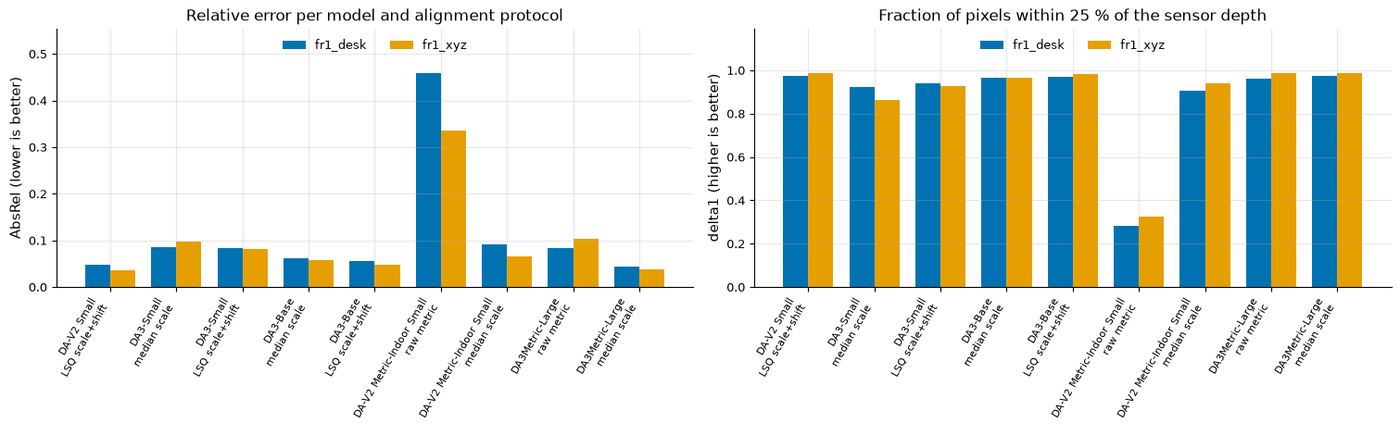

In [4]:
# --- AbsRel and delta1 per sequence, model and protocol ---
# One bar per (model, protocol); the two panels share the model order and colours.
combos = [(k, p) for k in order for p in md.PROTOCOLS[md.MODELS[k].output]]
names = [f"{md.MODELS[k].label}\n{md.PROTOCOL_LABELS[p]}" for k, p in combos]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, metric, label in [(axes[0], "abs_rel", "AbsRel (lower is better)"),
                          (axes[1], "delta1", "delta1 (higher is better)")]:
    width = 0.38
    for j, seq_name in enumerate(["fr1_desk", "fr1_xyz"]):
        s = summary[summary["sequence"] == seq_name].set_index(["model", "protocol"])
        vals = [s.loc[(k, p), metric] for k, p in combos]
        x = np.arange(len(combos)) + (j - 0.5) * width
        ax.bar(x, vals, width, label=seq_name, color=viz.color(j, unit=True))
    ax.set_xticks(np.arange(len(combos)), names, rotation=60, ha="right", fontsize=8)
    ax.set_ylabel(label)
    ax.set_ylim(0, 1.15 * ax.get_ylim()[1])
    ax.legend(loc="upper center", ncol=2)
axes[0].set_title("Relative error per model and alignment protocol")
axes[1].set_title("Fraction of pixels within 25 % of the sensor depth")
plt.show()

## Scale stability over time

A robot needs the depth scale to be **consistent from frame to frame**. Otherwise a mapping
system fuses inconsistent geometry, and a grasp planner sees objects change size. For every frame
the median protocol fits $s_t = \operatorname{median}(z^*)/\operatorname{median}(\hat z_t)$.
- For a **metric** model, $s_t = 1$ means perfect scale, and the spread of $s_t$ is the scale jitter you would get at run time.
- For a **relative** model, $s_t$ is in arbitrary units. Only its *relative* variation $s_t / \bar s$ matters: if it varies, a single calibration of the scale cannot fix all frames.

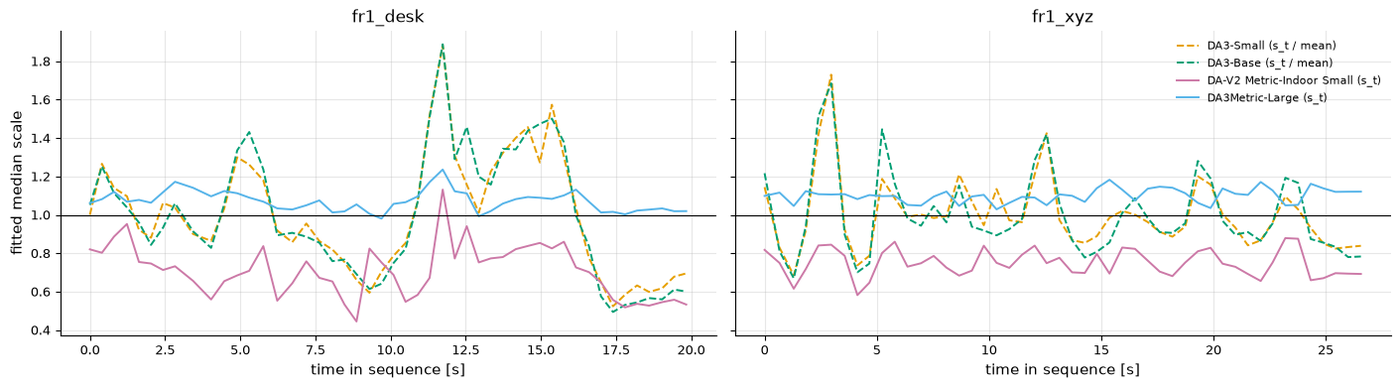

mean scale    std  \
sequence label                                          
fr1_desk DA-V2 Metric-Indoor Small       0.709  0.138   
         DA3-Base                        1.300  0.432   
         DA3-Small                       1.252  0.380   
         DA3Metric-Large                 1.070  0.052   
fr1_xyz  DA-V2 Metric-Indoor Small       0.749  0.070   
         DA3-Base                        1.309  0.281   
         DA3-Small                       1.257  0.235   
         DA3Metric-Large                 1.100  0.036   

                                    coefficient of variation  
sequence label                                                
fr1_desk DA-V2 Metric-Indoor Small                     0.195  
         DA3-Base                                      0.332  
         DA3-Small                                     0.303  
         DA3Metric-Large                               0.049  
fr1_xyz  DA-V2 Metric-Indoor Small                     0.094  
         DA3-Base                                      0.215  
         DA3-Small                                     0.187  
         DA3Metric-Large                               0.033

In [5]:
# --- Per-frame fitted scale over time (median protocol) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, seq_name in zip(axes, ["fr1_desk", "fr1_xyz"]):
    for i, key in enumerate(order[1:]):  # DA-V2 relative has no median protocol
        f = per_frame[(per_frame["sequence"] == seq_name) & (per_frame["model"] == key)
                      & (per_frame["protocol"] == "median")].sort_values("timestamp")
        t = f["timestamp"] - f["timestamp"].min()
        rel_scale = f["scale"] / (1.0 if md.MODELS[key].output == "metric" else f["scale"].mean())
        style = "-" if md.MODELS[key].output == "metric" else "--"
        ax.plot(t, rel_scale, style, color=viz.color(i + 1, unit=True), lw=1.4,
                label=f"{md.MODELS[key].label} ({'s_t' if md.MODELS[key].output == 'metric' else 's_t / mean'})")
    ax.axhline(1.0, color="k", lw=0.8)
    ax.set_xlabel("time in sequence [s]")
    ax.set_title(seq_name)
axes[0].set_ylabel("fitted median scale")
axes[1].legend(fontsize=8, loc="best")
plt.show()

stab = (per_frame[per_frame["protocol"] == "median"].groupby(["sequence", "label"])["scale"]
        .agg(["mean", "std"]).assign(cv=lambda d: d["std"] / d["mean"]))
stab.columns = ["mean scale", "std", "coefficient of variation"]
stab.round(3)

## Error vs distance

The per-pixel AbsRel is accumulated over all frames in bins of sensor depth (`md.binned_errors`).
Two effects compete. Kinect noise grows roughly with $z^2$, so the GT itself gets worse with
distance. Meanwhile far, textureless walls and the cluttered near field each have their own failure modes.

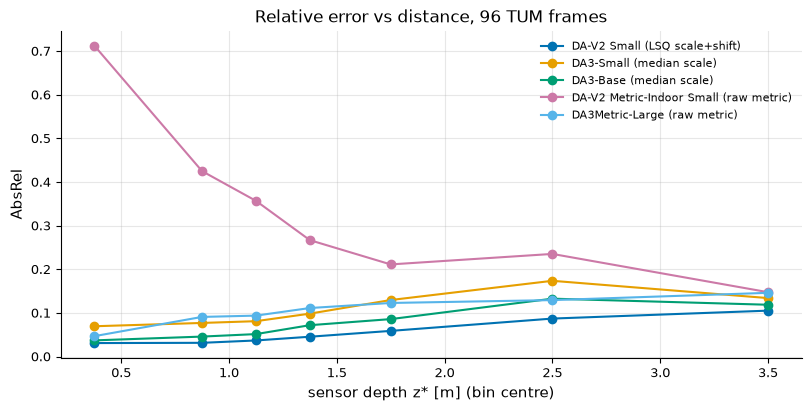

share of valid pixels per bin: {'0.0-0.75': 0.143, '0.75-1.0': 0.36, '1.0-1.25': 0.218, '1.25-1.5': 0.112, '1.5-2.0': 0.082, '2.0-3.0': 0.066, '3.0-10.0': 0.02}


In [6]:
# --- AbsRel per GT-depth bin (pixel-weighted over both sequences) ---
proto_main = {"disparity": "lsq", "depth": "median", "metric": "none"}
fig, ax = plt.subplots(figsize=(8, 4))
for i, key in enumerate(order):
    b = bins[(bins["model"] == key) & (bins["protocol"] == proto_main[md.MODELS[key].output])].copy()
    b["err_sum"] = b["abs_rel"].fillna(0) * b["n_pixels"]
    g = b.groupby(["bin_lo_m", "bin_hi_m"], as_index=False)[["err_sum", "n_pixels"]].sum()
    g = g[g["n_pixels"] > 20000]  # skip nearly empty bins
    centers = 0.5 * (g["bin_lo_m"] + g["bin_hi_m"].clip(upper=4.0))
    ax.plot(centers, g["err_sum"] / g["n_pixels"], "o-", color=viz.color(i, unit=True),
            label=f"{md.MODELS[key].label} ({md.PROTOCOL_LABELS[proto_main[md.MODELS[key].output]]})")
share = g["n_pixels"] / g["n_pixels"].sum()
ax.set_xlabel("sensor depth z* [m] (bin centre)")
ax.set_ylabel("AbsRel")
ax.set_title("Relative error vs distance, 96 TUM frames")
ax.legend(fontsize=8)
plt.show()
print("share of valid pixels per bin:", dict(zip(g["bin_lo_m"].astype(str) + "-" + g["bin_hi_m"].astype(str),
                                                  share.round(3))))

## A free camera calibration? DA3's predicted focal length

The any-view DA3 models also predict camera intrinsics. For a robot with an uncalibrated camera,
or one whose intrinsics change (zoom, a different resolution), that is useful, but only if it is
accurate. The calibrated fr1 focal length is $f_x = 517.3$, $f_y = 516.5$ px.

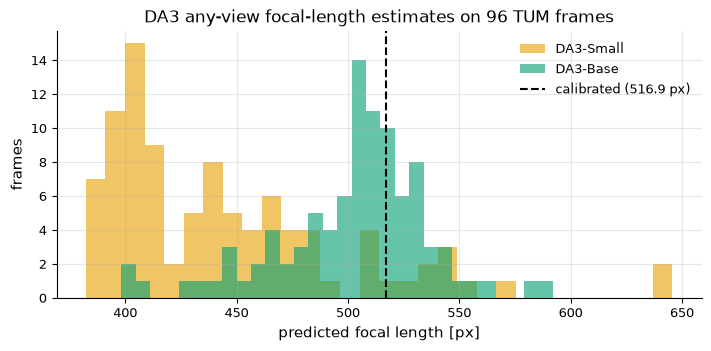

,mean,std,min,max
DA3-Small,445.3,54.6,382.3,645.7
DA3-Base,502.2,34.4,398.3,592.1


In [7]:
# --- Distribution of the predicted focal length (mean of fx, fy at 640x480) ---
fig, ax = plt.subplots(figsize=(7, 3.4))
foc = {}
for i, key in enumerate(["da3-small", "da3-base"]):
    f = per_frame[(per_frame["model"] == key) & (per_frame["protocol"] == "median")]["focal_pred_px"]
    foc[md.MODELS[key].label] = f.describe()[["mean", "std", "min", "max"]]
    ax.hist(f, bins=30, alpha=0.6, color=viz.color(i + 1, unit=True), label=md.MODELS[key].label)
ax.axvline(0.5 * (517.3 + 516.5), color="k", ls="--", label="calibrated (516.9 px)")
ax.set_xlabel("predicted focal length [px]")
ax.set_ylabel("frames")
ax.set_title("DA3 any-view focal-length estimates on 96 TUM frames")
ax.legend()
plt.show()
pd.DataFrame(foc).T.round(1)

## Failure cases

To find failure cases systematically, take the frames where the models are **worst**, and check
whether a simple image statistic explains them. Image sharpness is measured as the variance of the
Laplacian, $\operatorname{Var}(\nabla^2 I)$. It is low for motion-blurred frames, and `fr1_desk`
contains a lot of fast hand-held motion.

In [8]:
# --- Sharpness of every benchmark frame and its correlation with the error ---
# Spearman rank correlation (robust to outliers) between sharpness and AbsRel per model.
seqs = {name: md.load_tum(name) for name in meta["frames"]}
sharp = {}
for name, idxs in meta["frames"].items():
    for i in idxs:
        gray = cv2.cvtColor(seqs[name].rgb(i), cv2.COLOR_RGB2GRAY)
        sharp[name, i] = cv2.Laplacian(gray, cv2.CV_64F).var()
pf = per_frame.copy()
pf["sharpness"] = [sharp[s, f] for s, f in zip(pf["sequence"], pf["frame"])]
corr = {}
for key in order:
    f = pf[(pf["model"] == key) & (pf["protocol"] == proto_main[md.MODELS[key].output])]
    corr[md.MODELS[key].label] = float(f[["sharpness", "abs_rel"]].corr(method="spearman").iloc[0, 1])
print("Spearman(sharpness, AbsRel):", {k: round(v, 2) for k, v in corr.items()})

# Worst frames of DA3-BASE (median protocol) - the strongest relative model here.
f = pf[(pf["model"] == "da3-base") & (pf["protocol"] == "median")]
worst = f.nlargest(3, "abs_rel")[["sequence", "frame", "abs_rel", "sharpness", "gt_median_m"]]
best = f.nsmallest(1, "abs_rel")[["sequence", "frame", "abs_rel", "sharpness", "gt_median_m"]]
cases = pd.concat([best.assign(kind="best"), worst.assign(kind="worst")]).reset_index(drop=True)
cases

Spearman(sharpness, AbsRel): {'DA-V2 Small': -0.43, 'DA3-Small': 0.14, 'DA3-Base': -0.25, 'DA-V2 Metric-Indoor Small': -0.02, 'DA3Metric-Large': -0.1}


,sequence,frame,abs_rel,sharpness,gt_median_m,kind
0,fr1_desk,499,0.021601,133.704827,0.5770,best
1,fr1_desk,158,0.136891,97.226807,1.2164,worst
2,fr1_desk,377,0.108397,122.691552,1.2746,worst
3,fr1_xyz,151,0.104919,251.465335,1.1832,worst


Now run three models on these four frames (the best frame plus the three worst) and look at the
error maps: DA-V2 Small (LSQ in 1/z), DA3-BASE (median scale) and DA3METRIC-LARGE (raw metres).
Models are loaded one at a time to keep the VRAM low.

In [9]:
# --- Re-run three models on the selected frames and collect aligned depth + error maps ---
K = seqs["fr1_desk"].camera.K
frames = [(r.sequence, int(r.frame)) for r in cases.itertuples()]
fail_keys = ["da2-small", "da3-base", "da3metric-large"]
fail = {}
for key in fail_keys:
    model = md.DepthModel(key, device=str(device))
    for s, i in frames:
        gt_i = seqs[s].depth(i)
        p = model.predict(seqs[s].rgb(i), K)
        r = md.evaluate_frame(p.values, p.output, gt_i, [proto_main[p.output]])[proto_main[p.output]]
        fail[key, s, i] = (r["depth"], md.abs_rel_map(r["depth"], gt_i), r["abs_rel"])
    del model
    md.free_cuda()
print("evaluated", len(fail), "model-frame pairs")

evaluated 12 model-frame pairs


## Results

The main figure summarises the benchmark: accuracy of each model under its main protocol against
network forward time, with peak VRAM as marker area. The failure-case grid and the summary table follow.

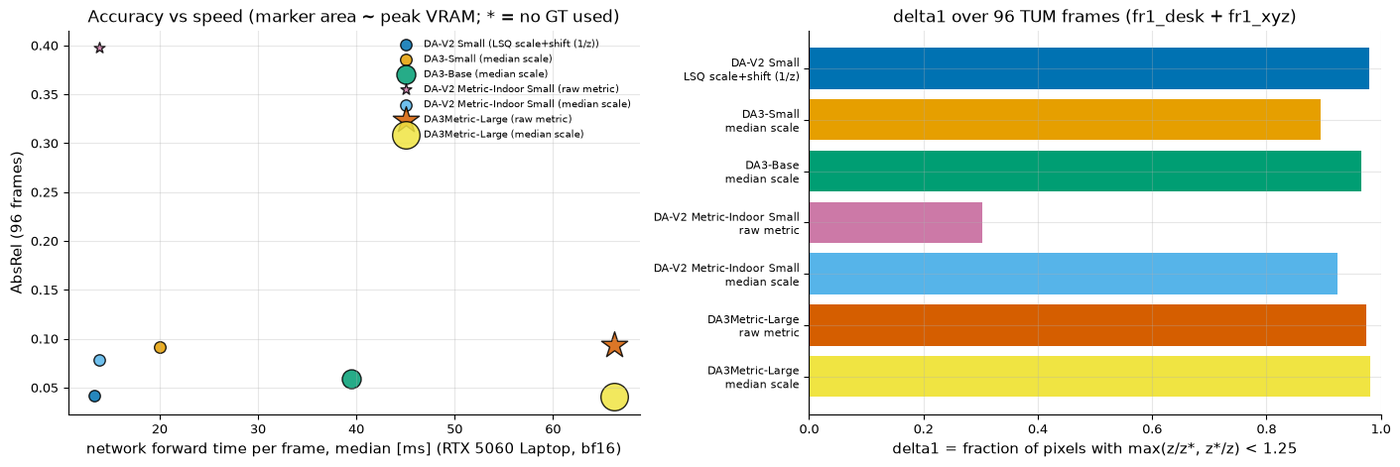

In [10]:
# --- Benchmark summary figure: accuracy vs network time (marker area = peak VRAM) + delta1 ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for i, r in headline.iterrows():
    proto_lbl = r["protocol"]
    marker = "o" if r["uses GT at test time"] else "*"
    axes[0].scatter(r["network [ms]"], r["AbsRel"], s=r["peak VRAM [MiB]"] / 4, marker=marker,
                    color=viz.color(i, unit=True), alpha=0.85, edgecolor="k",
                    label=f"{r['model']} ({proto_lbl})")
axes[0].set_xlabel("network forward time per frame, median [ms] (RTX 5060 Laptop, bf16)")
axes[0].set_ylabel("AbsRel (96 frames)")
axes[0].set_title("Accuracy vs speed (marker area ~ peak VRAM; * = no GT used)")
axes[0].legend(fontsize=7, loc="upper right")
labels = [f"{r['model']}\n{r['protocol']}" for _, r in headline.iterrows()]
axes[1].barh(labels, headline["delta1"], color=[viz.color(i, unit=True) for i in range(len(headline))])
axes[1].invert_yaxis()
axes[1].set_xlabel("delta1 = fraction of pixels with max(z/z*, z*/z) < 1.25")
axes[1].set_xlim(0, 1)
axes[1].set_title("delta1 over 96 TUM frames (fr1_desk + fr1_xyz)")
axes[1].tick_params(axis="y", labelsize=8)
viz.savefig(fig, PROJECT, "benchmark_summary")
plt.show()

The failure-case grid has one row per frame: the RGB image, the sensor depth, and the per-pixel
AbsRel of the three models. Grey means no sensor depth.

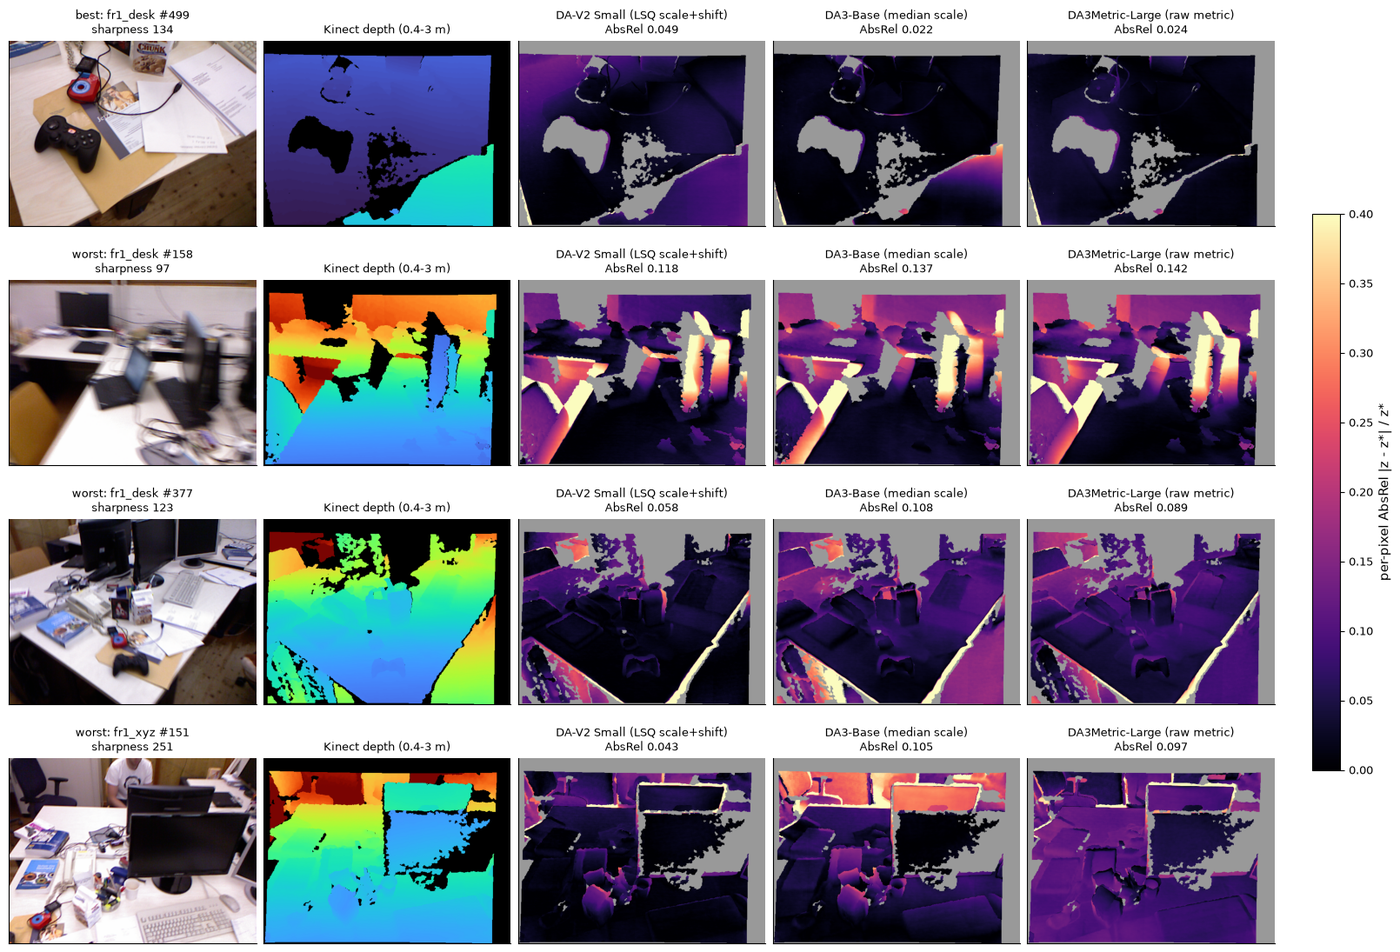

In [11]:
# --- Failure-case grid ---
fig, axes = plt.subplots(len(frames), 5, figsize=(16, 2.75 * len(frames)))
for row, ((s, i), kind) in enumerate(zip(frames, cases["kind"])):
    gt_i = seqs[s].depth(i)
    axes[row, 0].imshow(seqs[s].rgb(i))
    axes[row, 0].set_title(f"{kind}: {s} #{i}\nsharpness {sharp[s, i]:.0f}", fontsize=9)
    axes[row, 1].imshow(viz.colorize_depth(gt_i, 0.4, 3.0))
    axes[row, 1].set_title("Kinect depth (0.4-3 m)", fontsize=9)
    for col, key in enumerate(fail_keys, start=2):
        _, err, ar = fail[key, s, i]
        axes[row, col].set_facecolor("0.6")
        im = axes[row, col].imshow(err, cmap="magma", vmin=0, vmax=0.4)
        axes[row, col].set_title(f"{md.MODELS[key].label} ({md.PROTOCOL_LABELS[proto_main[md.MODELS[key].output]]})\nAbsRel {ar:.3f}", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes[:, 2:], label="per-pixel AbsRel |z - z*| / z*", shrink=0.6)
viz.savefig(fig, PROJECT, "failure_cases")
plt.show()

Summary table: the main-protocol numbers per sequence, which are the values quoted in the README.

In [12]:
# --- Summary table per sequence (main protocols) ---
keep = [(k, p) for k in order for p in main[md.MODELS[k].output]]
tab = summary[summary.apply(lambda r: (r["model"], r["protocol"]) in keep, axis=1)].copy()
tab["protocol"] = tab["protocol"].map(md.PROTOCOL_LABELS)
tab = tab.pivot_table(index=["label", "protocol"], columns="sequence",
                      values=["abs_rel", "delta1"], sort=False)
tab.style.format(precision=3)

### Takeaways

- **Per-frame-aligned relative depth looks excellent, but that number needs ground truth on every frame.**
  DA-V2 Small fitted in inverse depth reaches AbsRel 0.042 and $\delta_1$ 0.980 over 96 frames, and
  DA3-Base reaches 0.059 with a median scale. The scale DA3's relative models need varies by 19-33 %
  (coefficient of variation) from frame to frame, so one calibration cannot serve a whole
  sequence (Exercise 1 quantifies this). DA-V2 Small even beats DA3-Base under LSQ alignment here
  (0.042 vs 0.052). It processes images at 518x686 rather than 378x504, and it gets two free parameters per frame.
- **DA3METRIC-LARGE is the only model here that is usable as metric depth without a sensor.**
  Its raw AbsRel is 0.094 and $\delta_1$ 0.974. Its scale is stable to within 3-5 % (CV) but biased:
  the median scale of 1.07 on `fr1_desk` and 1.10 on `fr1_xyz` means it predicts about 7-9 % too close.
  Once the global scale is removed, its shape is the best of all five models (AbsRel 0.041).
- **DA-V2 Metric-Indoor Small does not transfer to TUM in metres.** Raw AbsRel is 0.398 and
  $\delta_1$ 0.304. A median scale of about 0.71-0.75 means its depths are about 1.34-1.41 times too large, even
  though its shape is reasonable (0.079 after median scaling). It was fine-tuned on synthetic
  Hypersim images with an implicit camera, while DA3METRIC takes the real focal length as an input.
- **Every model fits easily on an 8 GB laptop GPU.** Peak VRAM ranges from 269 MiB to 1.6 GB, and
  the network forward pass from about 13-14 ms (the two DA-V2 Small models) to about 66 ms (DA3METRIC-LARGE) per
  frame at batch 1. For the small models, end-to-end latency is dominated by CPU pre-processing,
  which is the first thing to move to the GPU when deploying (project 14).
- **Error grows with distance.** For example, DA3METRIC-LARGE's raw AbsRel rises from 0.047 below
  0.75 m to 0.146 beyond 3 m. Most TUM pixels are within 1.5 m (the desk).
- **Blur explains only part of the failures, and part of the "error" sits in the ground truth.**
  The rank correlation between sharpness and error is moderate for DA-V2 Small and weak or absent
  for the other models. In the worst frames the error concentrates in thin bands along depth
  discontinuities (desk edges, monitor sides), and all three models show *the same* bands.
  That points at the reference rather than at the networks. RGB and depth are captured at
  slightly different times (associated within 20 ms), and during the fast hand-held motion of
  `fr1_desk` the depth edges shift with respect to the blurred image. The remaining errors are
  model errors: the far background seen through gaps, and the scale of whole surfaces (`fr1_xyz` #151).

## Exercises

Solutions: `projects/08_monocular_depth/solutions/solutions_02.py`.

**Exercise 1: one scale per sequence.** A robot could calibrate the scale of a relative model
once (for example against a known object) and then keep it fixed. Run DA3-BASE on the 48 `fr1_desk` frames, fit **one**
median scale over all of them, and compare the AbsRel with the per-frame median protocol. How
much of the "relative" accuracy survives a fixed scale?

In [13]:
# --- Exercise 1: per-sequence (global) scale for DA3-BASE ---
# TODO: predict the 48 fr1_desk frames (meta["frames"]["fr1_desk"]), compute
# s = median over frames of median(z*)/median(z_hat), then md.evaluate_frame(s * z_hat, "metric", gt, ["none"]).

**Exercise 2: edges vs flat regions.** Split the valid pixels into *depth edges* (where the
relative GT depth gradient $\|\nabla z^*\| / z^* > 0.05$ per pixel, dilated by 2 px) and the rest.
Compute the AbsRel of DA3-BASE and DA-V2 Small separately on both sets. What fraction of the total error comes from edges?

In [14]:
# --- Exercise 2: AbsRel on depth edges vs flat regions ---
# TODO: build the edge mask with np.gradient + cv2.dilate, then pass mask=... to
# cvlab.metrics.depth_metrics for the aligned predictions.

**Exercise 3: calibrate a metric model's scale on one sequence and transfer it.** Use the
per-frame `scale` column (median protocol) of DA3METRIC-LARGE on `fr1_desk` to estimate a fixed
correction factor $c$. Apply it to the raw predictions on `fr1_xyz` and report the AbsRel before and after.
Does a scale learned in one room transfer to another sequence from the same camera?

In [15]:
# --- Exercise 3: transfer a scale correction from fr1_desk to fr1_xyz ---
# TODO: c = per_frame[(model == "da3metric-large") & (protocol == "median") & (sequence == "fr1_desk")]["scale"].median();
# then re-run DA3METRIC-LARGE on fr1_xyz frames and evaluate c * prediction with protocol "none".